In [1]:
import os
import json
import random
import shutil
import easyocr
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from ultralytics import YOLO
from transformers import AutoModelForImageTextToText, AutoProcessor

c:\Users\Cristina\miniconda3\envs\VC_P4b\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ==========================================================
# 1. RANDOMNESS AND TRAINING SEED
# ==========================================================
SEED = 42


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def get_random(seed=SEED):
    """Get a Python Random instance with a given seed. Default to global seed."""

    return random.Random(seed)


set_seed(SEED)
print(f"Training seed: {SEED}")

Training seed: 42


In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.cuda.is_available())

True


In [4]:
plate_detector_960_batch_16_small = YOLO(
    "../P4a/runs/detect/runs_plate/plate_detector_960_BATCH_16_small/weights/best.pt"
)
plate_detector_960_batch_16_small.to(device)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_runnin

### EasyOCR

In [ ]:
reader_easy = easyocr.Reader(["es"], gpu=torch.cuda.is_available())


0: 960x736 2 license_plates, 98.4ms
Speed: 8.7ms preprocess, 98.4ms inference, 2.3ms postprocess per image at shape (1, 3, 960, 736)
Results saved to C:\Users\Cristina\Documents\Projects\computer-vision\P4\P4b\runs\detect\predict-6
1 label saved to C:\Users\Cristina\Documents\Projects\computer-vision\P4\P4b\runs\detect\predict-6\labels


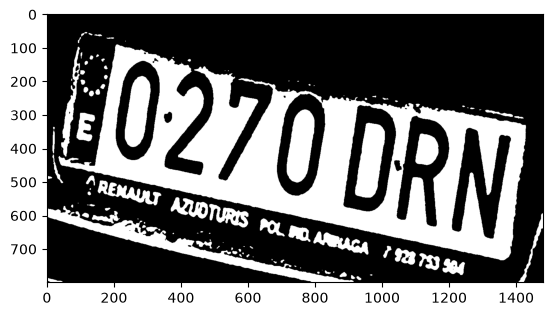

Matrícula detectada: 0270DRN


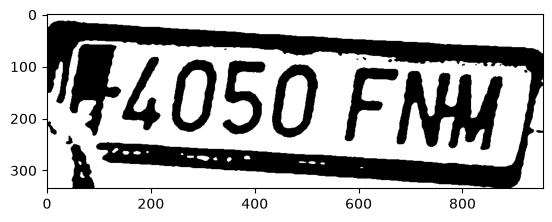

Matrícula detectada: No se detectó matrícula válida


In [30]:
img = cv2.imread("../../image-dataset/prac4VC_dataset/images/0270DRN.JPG")

results = plate_detector_960_batch_16_small.predict(source=img, save=True, save_txt=True, conf=0.5, device=device)
for box in results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    pad = 5
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
            max(0, int(x1) - pad) : min(w, int(x2) + pad),
        ].copy() 
    recorte_grande = cv2.resize(
        recorte, None, fx=5, fy=5, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)  
    leer_con_easyocr(recorte_gris)
    gris_suave = cv2.GaussianBlur(recorte_gris, (5, 5), 0)
    _, recorte_bin = cv2.threshold(gris_suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
    plt.imshow(cv2.cvtColor(recorte_bin, cv2.COLOR_BGR2RGB))
    plt.show()
    texto = reader_easy.readtext(
    recorte_bin, detail=0, allowlist="0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    )    

    matricula = "No se detectó matrícula válida"
    for t in texto:
        t_limpio = t.replace(" ", "")
        if len(t_limpio) == 7:
            matricula = t_limpio
    print("Matrícula detectada:", matricula)

## Paddle OCR 

In [ ]:
import os
import torch
from transformers import AutoModel, AutoTokenizer

In [ ]:
if not torch.cuda.is_available():
    torch.Tensor.cuda = lambda self, *a, **k: self
    torch.nn.Module.cuda = lambda self, *a, **k: self

In [ ]:
model_name = "baidu/Unlimited-OCR"
path_image = "../../image-dataset/prac4VC_dataset/images/0270DRN.JPG"
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModel.from_pretrained(
    model_name,
    trust_remote_code=True,
    use_safetensors=True,
    torch_dtype=torch.bfloat16,
)
model = model.eval().cuda()

In [ ]:
model.infer(
    tokenizer,
    prompt="<image>document parsing.",
    image_file=path_image,
    output_path=path_image.replace(".jpg", "_output_Unlimited"),
    base_size=1024,
    image_size=640,
    crop_mode=True,
    max_length=32768,
    no_repeat_ngram_size=35,
    ngram_window=128,
    save_results=True,
)

# SmolVLM


In [5]:
from transformers import AutoModelForImageTextToText, AutoProcessor

# CELDA DE CARGA (ejecutar solo una vez)
processor = AutoProcessor.from_pretrained(
    "HuggingFaceTB/SmolVLM-Instruct",
    size={"shortest_edge": 768, "longest_edge": 768},
)
model_vlm = AutoModelForImageTextToText.from_pretrained(
    "HuggingFaceTB/SmolVLM-Instruct",
    dtype=torch.bfloat16,
    _attn_implementation="eager",
    device_map="cuda",  # carga los pesos directamente en la GPU
)
model_vlm.eval()

Idefics3ForConditionalGeneration(
  (model): Idefics3Model(
    (vision_model): Idefics3VisionTransformer(
      (embeddings): Idefics3VisionEmbeddings(
        (patch_embedding): Conv2d(3, 1152, kernel_size=(14, 14), stride=(14, 14), padding=valid)
        (position_embedding): Embedding(729, 1152)
      )
      (encoder): Idefics3Encoder(
        (layers): ModuleList(
          (0-26): 27 x Idefics3EncoderLayer(
            (self_attn): Idefics3VisionAttention(
              (k_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (v_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (q_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (out_proj): Linear(in_features=1152, out_features=1152, bias=True)
            )
            (layer_norm1): LayerNorm((1152,), eps=1e-06, elementwise_affine=True)
            (mlp): Idefics3VisionMLP(
              (activation_fn): GELUTanh()
              (fc1): Linear(in_feature

In [6]:
print(f"VRAM usada: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM usada: 4.22 GB



0: 960x736 2 license_plates, 217.1ms
Speed: 69.2ms preprocess, 217.1ms inference, 1.6ms postprocess per image at shape (1, 3, 960, 736)


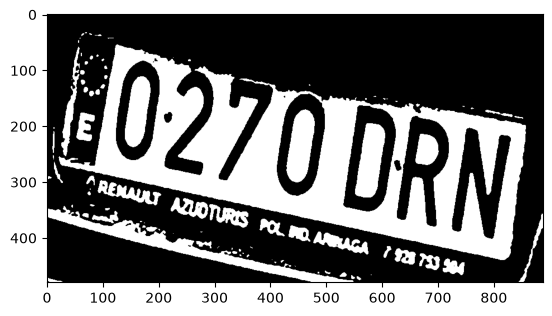

SmolVLM leyó: 0270DRN


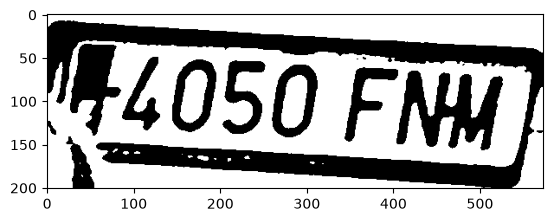

SmolVLM leyó: 4050FNH


In [ ]:
img = cv2.imread("../../image-dataset/prac4VC_dataset/images/0270DRN.JPG")

results = plate_detector_960_batch_16_small.predict(source=img, conf=0.5, device=device)

for box in results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    pad = 5
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
        max(0, int(x1) - pad) : min(w, int(x2) + pad),
    ].copy()

    recorte_grande = cv2.resize(
        recorte, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)
    gris_suave = cv2.GaussianBlur(recorte_gris, (5, 5), 0)
    _, recorte_bin = cv2.threshold(
        gris_suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )  
    
    pil_img = Image.fromarray(cv2.cvtColor(recorte_bin, cv2.COLOR_BGR2RGB))

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {
                    "type": "text",
                    "text": "Read the license plate text in this image. Reply ONLY with the alphanumeric characters of the plate, without spaces or hyphens.",
                },
            ],
        },
    ]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[pil_img], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = model_vlm.generate(**inputs, max_new_tokens=10)
        generated_text = processor.batch_decode(
            generated_ids[:, inputs["input_ids"].shape[1] :],
            skip_special_tokens=True,
        )[0]

    plt.imshow(cv2.cvtColor(recorte_bin, cv2.COLOR_BGR2RGB))
    plt.show()
    print("SmolVLM leyó:", generated_text.strip())

In [8]:
import time
import re
from difflib import SequenceMatcher
import pandas as pd


def limpiar_matricula(texto):
    return re.sub(r"[^A-Z0-9]", "", str(texto).upper())


# 2. Cargar imágenes del dataset junto con sus matrículas reales de los JSON
dataset_dir = Path("../../image-dataset/prac4VC_dataset")
images_dir = dataset_dir / "images"
annotations_dir = dataset_dir / "annotations"

muestras_dataset = []
for img_path in sorted(images_dir.iterdir()):
    if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue
    json_path = annotations_dir / f"{img_path.stem}.json"
    if not json_path.exists():
        continue

    with open(json_path, "r", encoding="utf-8") as f:
        anotaciones = json.load(f)

    # Extraer matrículas reales válidas (ignorando vacías o placeholders '0000AAA')
    placas_reales = [
        limpiar_matricula(a.get("plate", ""))
        for a in anotaciones
        if limpiar_matricula(a.get("plate", "")) not in ["", "0000AAA"]
    ]

    if len(placas_reales) > 0:
        muestras_dataset.append((img_path, placas_reales))

# Seleccionar un subconjunto fijo de imágenes para evaluar en las mismas condiciones
rdm = get_random(SEED)
MAX_IMAGENES = 50  # Puedes cambiarlo (ej. 30, 50, 100)
muestras_eval = rdm.sample(
    muestras_dataset, min(MAX_IMAGENES, len(muestras_dataset))
)

print(
    f"Total imágenes válidas: {len(muestras_dataset)} | Seleccionadas para evaluar: {len(muestras_eval)}"
)

Total imágenes válidas: 212 | Seleccionadas para evaluar: 50


In [37]:
def preprocesar_recorte(img, box, pad=5):
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
        max(0, int(x1) - pad) : min(w, int(x2) + pad),
    ].copy()
    recorte_grande = cv2.resize(
        recorte, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)
    gris_suave = cv2.GaussianBlur(recorte_gris, (5, 5), 0)

    return gris_suave


def leer_con_easyocr(recorte_gris):
    t0 = time.perf_counter()
    textos = reader_easy.readtext(
        recorte_gris, detail=0, allowlist="0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    )
    t_inferencia = time.perf_counter() - t0

    candidato = limpiar_matricula("".join(textos))
    for t in textos:
        t_limpio = limpiar_matricula(t)
        if len(t_limpio) == 7:
            candidato = t_limpio
            break
    return candidato, t_inferencia


def leer_con_smolvlm(recorte_gris):
    t0 = time.perf_counter()
    pil_img = Image.fromarray(cv2.cvtColor(recorte_gris, cv2.COLOR_BGR2RGB))
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {
                    "type": "text",
                    "text": "Read the license plate text in this image. Reply ONLY with the alphanumeric characters of the plate, without spaces or hyphens.",
                },
            ],
        }
    ]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[pil_img], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = model_vlm.generate(**inputs, max_new_tokens=10)
        generated_text = processor.batch_decode(
            generated_ids[:, inputs["input_ids"].shape[1] :],
            skip_special_tokens=True,
        )[0]

    t_inferencia = time.perf_counter() - t0
    return limpiar_matricula(generated_text), t_inferencia


def calcular_metricas_ocr(prediccion, placas_reales):
    if not prediccion:
        return 0, 0.0, ""
    mejor_real = max(
        placas_reales, key=lambda r: SequenceMatcher(None, prediccion, r).ratio()
    )
    similitud = SequenceMatcher(None, prediccion, mejor_real).ratio()
    acierto_exacto = int(prediccion == mejor_real)
    return acierto_exacto, similitud, mejor_real

In [38]:
resultados_comparativa = []

for idx, (img_path, placas_reales) in enumerate(muestras_eval, 1):
    img = cv2.imread(str(img_path))
    if img is None:
        continue

    # 1. Detectar matrícula con plate_detector_960_batch_16_small
    t0_yolo = time.perf_counter()
    preds_yolo = plate_detector_960_batch_16_small.predict(
        source=img, conf=0.5, verbose=False, device=device
    )
    t_yolo = time.perf_counter() - t0_yolo

    cajas = preds_yolo[0].boxes

    if len(cajas) == 0:
        for nombre_ocr in ["EasyOCR", "SmolVLM"]:
            resultados_comparativa.append(
                {
                    "imagen": img_path.name,
                    "modelo_ocr": nombre_ocr,
                    "matricula_real": placas_reales[0],
                    "prediccion": "",
                    "acierto_exacto": 0,
                    "similitud_caracteres": 0.0,
                    "tiempo_ocr_s": 0.0,
                    "tiempo_total_s": t_yolo,
                }
            )
        continue

    # 2. Evaluar EasyOCR y SmolVLM sobre cada recorte detectado
    for box in cajas:
        recorte_gris = preprocesar_recorte(img, box)

        # --- EasyOCR ---
        pred_easy, t_easy = leer_con_easyocr(recorte_gris)
        exacto_easy, sim_easy, real_easy = calcular_metricas_ocr(
            pred_easy, placas_reales
        )
        resultados_comparativa.append(
            {
                "imagen": img_path.name,
                "modelo_ocr": "EasyOCR",
                "matricula_real": real_easy or placas_reales[0],
                "prediccion": pred_easy,
                "acierto_exacto": exacto_easy,
                "similitud_caracteres": sim_easy,
                "tiempo_ocr_s": t_easy,
                "tiempo_total_s": t_yolo + t_easy,
            }
        )

        # --- SmolVLM ---
        pred_vlm, t_vlm = leer_con_smolvlm(recorte_gris)
        exacto_vlm, sim_vlm, real_vlm = calcular_metricas_ocr(pred_vlm, placas_reales)
        resultados_comparativa.append(
            {
                "imagen": img_path.name,
                "modelo_ocr": "SmolVLM",
                "matricula_real": real_vlm or placas_reales[0],
                "prediccion": pred_vlm,
                "acierto_exacto": exacto_vlm,
                "similitud_caracteres": sim_vlm,
                "tiempo_ocr_s": t_vlm,
                "tiempo_total_s": t_yolo + t_vlm,
            }
        )

    if idx % 10 == 0 or idx == len(muestras_eval):
        print(f"Procesadas {idx}/{len(muestras_eval)} imágenes...")

# Convertir a DataFrame y mostrar tabla resumen comparando EasyOCR vs SmolVLM
df_resultados = pd.DataFrame(resultados_comparativa)

resumen = (
    df_resultados.groupby("modelo_ocr")
    .agg(
        matriculas_evaluadas=("imagen", "count"),
        tasa_acierto_exacto_pct=("acierto_exacto", lambda x: round(x.mean() * 100, 2)),
        similitud_media_pct=(
            "similitud_caracteres",
            lambda x: round(x.mean() * 100, 2),
        ),
        tiempo_medio_ocr_ms=("tiempo_ocr_s", lambda x: round(x.mean() * 1000, 2)),
        tiempo_medio_total_ms=("tiempo_total_s", lambda x: round(x.mean() * 1000, 2)),
    )
    .reset_index()
)

display(resumen)

Procesadas 10/50 imágenes...
Procesadas 20/50 imágenes...
Procesadas 30/50 imágenes...
Procesadas 40/50 imágenes...
Procesadas 50/50 imágenes...


,modelo_ocr,matriculas_evaluadas,tasa_acierto_exacto_pct,similitud_media_pct,tiempo_medio_ocr_ms,tiempo_medio_total_ms
0,EasyOCR,107,21.50,47.99,472.93,523.45
1,SmolVLM,107,35.51,67.47,1559.95,1610.47


## Testing with video FELIX

In [ ]:
import os
import json
import random
import shutil
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import csv
import yaml
from collections import Counter, defaultdict

import torch
from ultralytics import YOLO

In [ ]:
YOLO_TRACKER_CONFIG = {
    "tracker_type": "botsort",  # Used for tracking license plates across frames
    "fuse_score": True,  # Fuse: Use detection confidence score to improve tracking
    "gmc_method": "sparseOptFlow",  # Use sparse optical flow for motion compensation
    "with_reid": False,  # REID: Use appearance features for re-identification (slower, but more robust)
    "appearance_thresh": 0.7,  # Appearance similarity threshold for re-identification
    "match_thresh": 0.75,  # Matching threshold for associating detections to existing tracks
    "new_track_thresh": 0.25,  # Confidence threshold for creating new tracks
    "proximity_thresh": 0.5,  # Proximity threshold for associating detections to existing tracks
    "track_high_thresh": 0.25,  # Confidence threshold for keeping tracks alive
    "track_low_thresh": 0.1,  # Confidence threshold for terminating tracks
    "track_buffer": 90,  # Number of frames to keep a track alive without detections
}
YOLO_TRACKER_CONFIG_PATH = Path("yolo_tracker_file.yaml").resolve()

with open(YOLO_TRACKER_CONFIG_PATH, "w") as tracker_file:
    yaml.dump(YOLO_TRACKER_CONFIG, tracker_file, default_flow_style=False)

In [ ]:
class PedestrianOcclusionManager:
    """
    Manages the continuity of pedestrian identities when they suffer occlusions
    (e.g., when a vehicle passes in front of a person).
    """

    def __init__(self, max_gap_frames=90, max_distance=220, min_similarity=0.60):
        self.max_gap_frames = max_gap_frames
        self.max_distance = max_distance
        self.min_similarity = min_similarity

        self.id_remap = {}  # raw_yolo_id -> canonical_id
        self.lost_tracks = {}  # canonical_id -> dict with info of last known state
        self.active_tracks = (
            {}
        )  # canonical_id -> dict with last box and color histogram

    def resolve_id(self, raw_id):
        curr = raw_id
        visited = set()
        while curr in self.id_remap and curr not in visited:
            visited.add(curr)
            curr = self.id_remap[curr]

        return curr

    @staticmethod
    def extract_color_hist(frame, box):
        x1, y1, x2, y2 = box
        crop = frame[max(0, y1) : max(0, y2), max(0, x1) : max(0, x2)]
        if crop.size == 0 or crop.shape[0] < 6 or crop.shape[1] < 6:
            return None

        hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
        hist = cv2.calcHist([hsv], [0, 1], None, [16, 16], [0, 180, 0, 256])
        cv2.normalize(hist, hist, 0, 1, cv2.NORM_MINMAX)
        return hist

    @staticmethod
    def get_center(box):
        return ((box[0] + box[2]) / 2.0, (box[1] + box[3]) / 2.0)

    @staticmethod
    def compute_distance(p1, p2):
        """Euclidean distance between two points p1 and p2, where each point is (x, y)"""
        return ((p1[0] - p2[0]) ** 2 + (p1[1] - p2[1]) ** 2) ** 0.5

    def _is_track_known(self, raw_id, canonical_id):
        return raw_id in self.id_remap or canonical_id in self.active_tracks

    def _check_lost_tracks(self, current_frame, p_center, p_hist):
        # If it's a new track we don't know created by YOLO
        best_match_id = None
        best_score = -1.0

        for lost_id, lost_info in list(self.lost_tracks.items()):
            # Check if the lost track is too old
            gap = current_frame - lost_info["last_frame"]
            if gap > self.max_gap_frames:
                continue

            # Check distance between last known position and current detection
            lost_center = self.get_center(lost_info["last_box"])
            dist = self.compute_distance(p_center, lost_center)
            max_allowed_dist = min(self.max_distance, 40.0 + gap * 3.5)
            if dist > max_allowed_dist:
                continue

            # HSV color histogram similarity (0.0 to 1.0, higher is more similar)
            similarity = 0.5
            if p_hist is not None and lost_info["color_hist"] is not None:
                similarity = cv2.compareHist(
                    p_hist, lost_info["color_hist"], cv2.HISTCMP_CORREL
                )

            # If the lost track was occluded by a vehicle and reappears nearby,
            # or if the similarity is high
            score = similarity - (dist / 1200.0)
            if (similarity >= self.min_similarity) or (
                lost_info["occluded_by_vehicle"] and dist < 90 and similarity > 0.35
            ):
                if score > best_score:
                    best_score = score
                    best_match_id = lost_id

        return best_match_id, best_score

    def _relink_track(self, raw_id, best_match_id):
        self.id_remap[raw_id] = best_match_id
        if best_match_id in self.lost_tracks:
            del self.lost_tracks[best_match_id]

    def _update_active_track(self, canonical_id, p_box, p_hist, current_frame):
        self.active_tracks[canonical_id] = {
            "last_frame": current_frame,
            "last_box": p_box,
            "color_hist": (
                p_hist
                if p_hist is not None
                else self.active_tracks.get(canonical_id, {}).get("color_hist")
            ),
        }

    def _process_yolo_tracks(self, people, frame, current_frame):
        current_canonical_ids = set()

        for person in people:
            raw_id = person["track_id"]
            if raw_id == "" or raw_id is None:
                continue

            canonical_id = self.resolve_id(raw_id)
            p_box = person["box"]
            p_center = self.get_center(p_box)
            p_hist = self.extract_color_hist(frame, p_box)

            if self._is_track_known(raw_id, canonical_id):
                continue  # Already known track, no need to check lost tracks

            # Check lost tracks for potential matches
            best_match_id, _ = self._check_lost_tracks(current_frame, p_center, p_hist)

            if best_match_id is not None:
                # Re-link track: assign original ID
                canonical_id = best_match_id
                self._relink_track(raw_id, best_match_id)

            person["track_id"] = canonical_id
            current_canonical_ids.add(canonical_id)

            # Update active tracks with the latest information
            self._update_active_track(canonical_id, p_box, p_hist, current_frame)

        return current_canonical_ids

    def _process_missing_people_in_frame(self, current_canonical_ids, vehicle_boxes):
        disappeared_ids = set(self.active_tracks.keys()) - current_canonical_ids
        for dis_id in disappeared_ids:
            dis_info = self.active_tracks[dis_id]
            dis_box = dis_info["last_box"]
            dis_center = self.get_center(dis_box)

            # Comprobar si desapareció solapado con un vehículo
            was_occluded = False
            for vx1, vy1, vx2, vy2 in vehicle_boxes:
                if (vx1 <= dis_center[0] <= vx2 and vy1 <= dis_center[1] <= vy2) or (
                    max(dis_box[0], vx1) < min(dis_box[2], vx2)
                    and max(dis_box[1], vy1) < min(dis_box[3], vy2)
                ):
                    was_occluded = True
                    break

            self.lost_tracks[dis_id] = {
                "last_frame": dis_info["last_frame"],
                "last_box": dis_box,
                "color_hist": dis_info["color_hist"],
                "occluded_by_vehicle": was_occluded,
            }
            del self.active_tracks[dis_id]

    def _cleanup_old_lost_tracks(self, current_frame):
        for lost_id in list(self.lost_tracks.keys()):
            if (
                current_frame - self.lost_tracks[lost_id]["last_frame"]
                > self.max_gap_frames
            ):
                del self.lost_tracks[lost_id]

    def process_people_in_frame(self, frame, people, current_frame, vehicle_boxes):
        """
        Process the people in the current frame, resolving ID switches due to occlusion.
        """

        # Process YOLO trackers and update active tracks
        current_canonical_ids = self._process_yolo_tracks(people, frame, current_frame)

        # Identify which pedestrians disappeared in this frame
        self._process_missing_people_in_frame(current_canonical_ids, vehicle_boxes)

        # Clean up lost tracks that have exceeded the maximum gap frames
        self._cleanup_old_lost_tracks(current_frame)

In [ ]:
class LicensePlateVideoProcessor:
    """
    Processes a video to detect and track vehicles, license plates and pedestrians.
    Applies occlusion management, hierarchical license plate memory and track class consensus.
    Saves the annotated video and generates the results CSV.
    """

    def __init__(
        self,
        vehicle_model,
        plate_model,
        tracker_config=YOLO_TRACKER_CONFIG_PATH,
        max_gap_frames=90,
        max_distance=220,
        apply_censoring=False,
    ):
        self.vehicle_model: YOLO = vehicle_model
        self.plate_model: YOLO = plate_model
        self.tracker_config = tracker_config
        self.occlusion_manager = PedestrianOcclusionManager(
            max_gap_frames=max_gap_frames, max_distance=max_distance
        )
        self.apply_censoring = apply_censoring

        self.video_width = None
        self.video_height = None
        self.video_fps = None
        self.video_total_frames = None

        self.vehicle_classes = {
            0: "person",
            2: "car",
            3: "motorbike",
            5: "bus",
            # 7: "truck",
        }

        self.csv_columns = [
            "fotograma",
            "tipo_objeto",
            "confianza",
            "identificador_tracking",
            "x1",
            "y1",
            "x2",
            "y2",
            "matrícula_en_su_caso",
            "confianza",
            "mx1",
            "my1",
            "mx2",
            "my2",
            "texto_matricula",
        ]

        # Store the history of license plate readings for each vehicle ID
        self.vehicle_plate_registry = defaultdict(
            lambda: {
                "seen_count": 0,
                "text_readings": [],
                "last_box": None,
                "last_conf": 0.0,
                "last_seen_frame": -1,
            }
        )

        # Store the history of detected classes for each track ID
        self.track_class_history = defaultdict(lambda: Counter())
        self.confirmed_plates = set()
        self.raw_detection_counts = {name: 0 for name in self.vehicle_classes.values()}
        self.raw_detection_counts["license_plate"] = 0

    def box_values(self, box):
        """
        Get the bounding box coordinates, confidence and track ID from a YOLO box object.
        """

        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
        confidence = float(box.conf[0])
        track_id = int(box.id[0]) if box.id is not None else ""

        return x1, y1, x2, y2, confidence, track_id

    def plate_belongs_to_vehicle(self, plate_box, vehicle_box):
        """
        Determine if a detected license plate belongs to a detected vehicle based on bounding box overlap and position.
        """

        px1, py1, px2, py2 = plate_box
        vx1, vy1, vx2, vy2 = vehicle_box

        # Test if center of plate is inside vehicle box
        pcx = (px1 + px2) / 2.0
        pcy = (py1 + py2) / 2.0
        if vx1 <= pcx <= vx2 and vy1 <= pcy <= vy2:
            return True

        # Check if the intersection of the two boxes is at least 50% of the plate area
        ix1 = max(px1, vx1)
        iy1 = max(py1, vy1)
        ix2 = min(px2, vx2)
        iy2 = min(py2, vy2)
        if ix1 < ix2 and iy1 < iy2:
            inter_area = (ix2 - ix1) * (iy2 - iy1)
            plate_area = max(1, (px2 - px1) * (py2 - py1))
            if (inter_area / plate_area) >= 0.5:
                return True

        return False

    def _prepare_video_writer(
        self, input_video_path, output_video_path, max_frames=None
    ):
        video_capture = cv2.VideoCapture(str(input_video_path))
        if not video_capture.isOpened():
            raise RuntimeError(f"Could not open video: {input_video_path}")

        self.video_width = int(video_capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        self.video_height = int(video_capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        self.video_fps = video_capture.get(cv2.CAP_PROP_FPS) or 25.0
        self.video_total_frames = int(video_capture.get(cv2.CAP_PROP_FRAME_COUNT))

        if max_frames is not None:
            self.video_total_frames = min(self.video_total_frames, max_frames)

        writer = cv2.VideoWriter(
            str(output_video_path),
            cv2.VideoWriter_fourcc(*"mp4v"),
            self.video_fps,
            (self.video_width, self.video_height),
        )

        return video_capture, writer

    def _detect_vehicles(self, frame, conf_threshold):
        return self.vehicle_model.track(
            frame,
            classes=list(self.vehicle_classes.keys()),
            conf=conf_threshold,
            persist=True,
            tracker=self.tracker_config,
            verbose=False,
        )

    def _detect_license_plates(self, frame, conf_threshold):
        return self.plate_model(
            frame,
            conf=conf_threshold,
            verbose=False,
        )

    def _classify_detections(self, vehicle_results):
        current_vehicles = []
        current_people = []
        vehicle_boxes = []
        if not vehicle_results or len(vehicle_results[0].boxes) == 0:
            return current_vehicles, current_people, vehicle_boxes

        for box in vehicle_results[0].boxes:
            x1, y1, x2, y2, conf, track_id = self.box_values(box)
            cls_id = int(box.cls[0])

            # Map the YOLO class ID to a human-readable type
            raw_type = self.vehicle_classes.get(cls_id)
            if raw_type is None:
                continue

            # Update raw class count
            self.raw_detection_counts[raw_type] += 1
            item = {
                "type": raw_type,
                "confidence": conf,
                "track_id": track_id,
                "box": (x1, y1, x2, y2),
            }

            if raw_type == "person":
                current_people.append(item)
            else:
                current_vehicles.append(item)
                vehicle_boxes.append((x1, y1, x2, y2))

        return current_vehicles, current_people, vehicle_boxes

    def _update_track_class_history(self, tracks: list):
        for track in tracks:
            tid = track["track_id"]
            if tid == "":
                continue

            self.track_class_history[tid][track["type"]] += 1
            # Use mode (moda) to determine the dominant class for this track
            dominant_type = self.track_class_history[tid].most_common(1)[0][0]
            track["type"] = dominant_type

    def _process_license_plates(self, plate_results, current_vehicles):
        current_plates = []
        if plate_results is None or len(plate_results) == 0:
            return current_plates

        # Process each detected license plate and associate it with a vehicle if possible
        for box in plate_results[0].boxes:
            px1, py1, px2, py2 = [int(v) for v in box.xyxy[0].tolist()]
            plate_conf = float(box.conf[0])

            current_plates.append(
                {
                    "box": (px1, py1, px2, py2),
                    "confidence": plate_conf,
                    "associated": False,
                }
            )

            self.raw_detection_counts["license_plate"] += 1

        for plate in current_plates:
            matched_vehicle = None
            for vehicle in current_vehicles:
                if self.plate_belongs_to_vehicle(plate["box"], vehicle["box"]):
                    matched_vehicle = vehicle
                    break

            if matched_vehicle is not None:
                plate["associated"] = True
                plate["vehicle_id"] = matched_vehicle["track_id"]
                if matched_vehicle["track_id"] != "":
                    self.confirmed_plates.add(matched_vehicle["track_id"])
            else:
                plate["vehicle_id"] = ""

        return current_plates

    def _write_vehicles_in_csv(
        self,
        csv_writer,
        annotated_frame,
        frame_number,
        current_vehicles,
        current_plates,
    ):
        for vehicle in current_vehicles:
            # Get bbox
            vx1, vy1, vx2, vy2 = vehicle["box"]
            v_id = vehicle["track_id"]

            # Did we find a license plate in this frame for this vehicle?
            plate_in_this_frame = next(
                (
                    plate
                    for plate in current_plates
                    if plate["associated"]
                    and self.plate_belongs_to_vehicle(plate["box"], vehicle["box"])
                ),
                None,
            )

            if plate_in_this_frame is not None:
                px1, py1, px2, py2 = plate_in_this_frame["box"]
                csv_writer.writerow(
                    [
                        frame_number,
                        vehicle["type"],
                        f"{vehicle['confidence']:.4f}",
                        v_id,
                        vx1,
                        vy1,
                        vx2,
                        vy2,
                        "yes",
                        f"{plate_in_this_frame['confidence']:.4f}",
                        px1,
                        py1,
                        px2,
                        py2,
                        f"{vehicle['type']}_{vehicle['track_id']}_plate",
                    ]
                )
            else:
                csv_writer.writerow(
                    [
                        frame_number,
                        vehicle["type"],
                        f"{vehicle['confidence']:.4f}",
                        v_id,
                        vx1,
                        vy1,
                        vx2,
                        vy2,
                        "no",
                        "",
                        "",
                        "",
                        "",
                        "",
                        "",
                    ]
                )

            # Draw vehicle bounding box in CYAN
            cv2.rectangle(annotated_frame, (vx1, vy1), (vx2, vy2), (255, 120, 0), 2)
            v_label = f"{vehicle['type']} ID:{v_id} {vehicle['confidence']:.2f}"
            cv2.putText(
                annotated_frame,
                v_label,
                (vx1, max(vy1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 140, 0),
                2,
            )

    def _write_people_to_csv(
        self, csv_writer, annotated_frame, frame_number, current_people
    ):
        for person in current_people:
            px1, py1, px2, py2 = person["box"]
            p_id = person["track_id"]

            csv_writer.writerow(
                [
                    frame_number,
                    person["type"],
                    f"{person['confidence']:.4f}",
                    p_id,
                    px1,
                    py1,
                    px2,
                    py2,
                    "no",
                    "",
                    "",
                    "",
                    "",
                    "",
                    "",
                ]
            )

            # Draw person bounding box in ORANGE
            cv2.rectangle(annotated_frame, (px1, py1), (px2, py2), (0, 165, 255), 2)
            p_label = f"{person['type']} ID:{p_id} {person['confidence']:.2f}"
            cv2.putText(
                annotated_frame,
                p_label,
                (px1, max(py1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 165, 255),
                2,
            )

    def _write_plates_to_csv(
        self, csv_writer, annotated_frame, frame_number, current_plates
    ):
        for plate in current_plates:
            px1, py1, px2, py2 = plate["box"]

            # Write orphan license plates
            if not plate["associated"]:
                csv_writer.writerow(
                    [
                        frame_number,
                        "license_plate",
                        f"{plate['confidence']:.4f}",
                        "",
                        px1,
                        py1,
                        px2,
                        py2,
                        "yes",
                        f"{plate['confidence']:.4f}",
                        px1,
                        py1,
                        px2,
                        py2,
                        "orphan_plate",
                    ]
                )

            # Draw license plate bounding box in GREEN
            cv2.rectangle(annotated_frame, (px1, py1), (px2, py2), (0, 255, 0), 2)
            plate_label = f"MATRICULA {plate['confidence']:.2f}".strip()
            cv2.putText(
                annotated_frame,
                plate_label,
                (px1, max(py1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (0, 255, 0),
                2,
            )

    def _write_frame_and_csv(
        self,
        frame,
        frame_number,
        csv_writer,
        current_vehicles,
        current_people,
        current_plates,
    ):
        annotated_frame = frame.copy()

        self._write_vehicles_in_csv(
            csv_writer, annotated_frame, frame_number, current_vehicles, current_plates
        )
        self._write_people_to_csv(
            csv_writer, annotated_frame, frame_number, current_people
        )
        self._write_plates_to_csv(
            csv_writer, annotated_frame, frame_number, current_plates
        )

        return annotated_frame

    def _create_hud_overlay(
        self, annotated_frame, frame_number, min_frames_to_confirm: int
    ):
        hud_overlay = annotated_frame.copy()
        cv2.rectangle(hud_overlay, (0, 0), (self.video_width, 40), (25, 25, 25), -1)
        cv2.addWeighted(hud_overlay, 0.65, annotated_frame, 0.35, 0, annotated_frame)

        # Get classes for HUD
        hud_confirmed = defaultdict(int)
        for tid, hist in self.track_class_history.items():
            if sum(hist.values()) >= min_frames_to_confirm:
                dom_cls = hist.most_common(1)[0][0]
                hud_confirmed[dom_cls] += 1

        hud_text = (
            f"Fotograma: {frame_number}/{self.video_total_frames} | "
            f"Personas: {hud_confirmed['person']} | "
            f"Coches: {hud_confirmed['car']} | "
            f"Motos: {hud_confirmed['motorbike']} | "
            f"Autobuses: {hud_confirmed['bus']} | "
            # f"Camiones: {hud_confirmed['truck']} | "
            f"Matrículas: {len(self.confirmed_plates)}"
        )
        cv2.putText(
            annotated_frame,
            hud_text,
            (12, 26),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (255, 255, 255),
            2,
        )

    def _apply_people_censor(self, annotated_frame, current_people):
        if not self.apply_censoring:
            return

        for person in current_people:
            px1, py1, px2, py2 = person["box"]

            # Apply blur to a person's bbox upper half
            censor_area = (px1, py1, px2, py1 + (py2 - py1) // 4)
            censor_crop = annotated_frame[
                censor_area[1] : censor_area[3], censor_area[0] : censor_area[2]
            ]
            if censor_crop.size > 0:
                blurred_crop = cv2.GaussianBlur(censor_crop, (25, 25), 30)
                annotated_frame[
                    censor_area[1] : censor_area[3], censor_area[0] : censor_area[2]
                ] = blurred_crop

    def _apply_incoming_car_censor(self, annotated_frame, current_vehicles):
        if not self.apply_censoring:
            return

        for vehicle in current_vehicles:
            if vehicle["confidence"] < 0.65:
                continue

            vx1, vy1, vx2, vy2 = vehicle["box"]
            # Apply blur to the car's bounding box
            censor_area = (vx1, vy1, vx2, vy1 + (vy2 - vy1) // 3)
            censor_crop = annotated_frame[
                censor_area[1] : censor_area[3], censor_area[0] : censor_area[2]
            ]
            if censor_crop.size > 0:
                blurred_crop = cv2.GaussianBlur(censor_crop, (25, 25), 30)
                annotated_frame[
                    censor_area[1] : censor_area[3], censor_area[0] : censor_area[2]
                ] = blurred_crop

    def _process_video_frame(
        self, frame, csv_writer, frame_number: int, conf_threshold: float
    ):
        # 1 - Process vehicle detection and tracking
        vehicle_results = self._detect_vehicles(frame, conf_threshold)

        # 2 - Process license plate detection and tracking
        plate_results = self._detect_license_plates(frame, conf_threshold)

        # 3 - Classify detections into vehicles and pedestrians
        current_vehicles, current_people, vehicle_boxes = self._classify_detections(
            vehicle_results
        )

        # 4 - Process pedestrian occlusion management
        self.occlusion_manager.process_people_in_frame(
            frame, current_people, frame_number, vehicle_boxes
        )

        # 5 - Update class history and assign dominant class for each track
        self._update_track_class_history(current_vehicles + current_people)

        # 6 - Process license plate readings
        current_plates = self._process_license_plates(plate_results, current_vehicles)

        # 7 - Write annotated frame to video and CSV
        annotated_frame = self._write_frame_and_csv(
            frame,
            frame_number,
            csv_writer,
            current_vehicles,
            current_people,
            current_plates,
        )

        # 8 - Apply optional face censoring
        self._apply_incoming_car_censor(annotated_frame, current_vehicles)
        self._apply_people_censor(annotated_frame, current_people)

        return annotated_frame

    def print_summary(self, output_video_path, output_csv_path, min_frames_to_confirm):
        confirmed_unique_objects = {
            name: set() for name in self.vehicle_classes.values()
        }
        # Count unique confirmed objects based on track class history
        for tid, hist in self.track_class_history.items():
            if sum(hist.values()) >= min_frames_to_confirm:
                dom_cls = hist.most_common(1)[0][0]
                if dom_cls in confirmed_unique_objects:
                    confirmed_unique_objects[dom_cls].add(tid)

        unique_counts = {
            cls_name: len(confirmed_unique_objects[cls_name])
            for cls_name in self.vehicle_classes.values()
        }
        unique_counts["license_plate"] = len(self.confirmed_plates)

        print("\n" + "=" * 60)
        print(" VIDEO PROCESSING SUMMARY")
        print("=" * 60)
        print(f"* Video output path: {output_video_path}")
        print(f"* Results CSV path:   {output_csv_path}")
        print("\n" + "-" * 60)
        print(" TOTAL COUNT OF CONFIRMED UNIQUE OBJECTS:")
        print("-" * 60)
        for obj_type, count in unique_counts.items():
            print(f"  * {obj_type:15s}: {count}")
        print("-" * 60)
        print(" RAW DETECTIONS PER FRAME:")
        for obj_type, count in self.raw_detection_counts.items():
            print(f"  * {obj_type:15s}: {count} total detections")
        print("=" * 60)

        return unique_counts, self.raw_detection_counts

    def process_video(
        self,
        input_video_path: Path | str,
        output_video_path: Path | str,
        output_csv_path: Path | str,
        conf_threshold=0.35,
        show_window=False,
        max_frames=None | int,
        min_frames_to_confirm=5,
    ):
        """
        Args:
            input_video_path (str or Path): Path to the input video file.
            output_video_path (str or Path): Path to save the annotated output video.
            output_csv_path (str or Path): Path to save the results CSV file.
            conf_threshold (float): Confidence threshold for detections (default: 0.35).
            show_window (bool): Whether to display the annotated video in a window (default: False).
            max_frames (int or None): Maximum number of frames to process (default: None, process all frames).
            min_frames_to_confirm (int): Minimum number of frames required to confirm an object's class (default: 5).
        """

        video_capture, video_writer = self._prepare_video_writer(
            input_video_path, output_video_path, max_frames
        )

        with open(output_csv_path, "w", newline="", encoding="utf-8") as csv_file:
            csv_writer = csv.writer(csv_file)
            csv_writer.writerow(self.csv_columns)

            frame_number = 0
            while video_capture.isOpened():
                ret, frame = video_capture.read()
                if not ret or (max_frames is not None and frame_number >= max_frames):
                    break

                frame_number += 1
                if frame_number % 10 == 0 or frame_number == 1:
                    print(
                        "Processing frame:",
                        frame_number,
                        "/",
                        self.video_total_frames,
                        end="\r",
                    )

                annotated_frame = self._process_video_frame(
                    frame, csv_writer, frame_number, conf_threshold
                )
                self._create_hud_overlay(
                    annotated_frame, frame_number, min_frames_to_confirm
                )

                video_writer.write(annotated_frame)
                if show_window:
                    cv2.imshow("Annotated Video", annotated_frame)
                    if cv2.waitKey(1) == 27:  # ESC key to exit
                        break

In [ ]:
VIDEO_INPUT_PATH = Path("plate_test_video.mp4").resolve()
VIDEO_OUTPUT_PATH = Path("yolo_dual_detections.mp4").resolve()
CSV_OUTPUT_PATH = Path("yolo_dual_detections.csv").resolve()
FRAMES_TO_CONFIRM_CLASS = 5
CONFIDENCE_THRESHOLD = 0.35
APPLY_CENSORING = True
COMPRESS_VIDEO = True

In [ ]:
BATCH_SIZE = 16
IMGSZ = 960
NOTEBOOK_DIR = Path.cwd()
CHOSEN_MODEL_TYPE = "small"

if (
    not (NOTEBOOK_DIR / "yolo").exists()
    and (NOTEBOOK_DIR / "P4" / "P4a" / "yolo").exists()
):
    NOTEBOOK_DIR = NOTEBOOK_DIR / "P4" / "P4a"

PROJECT = (NOTEBOOK_DIR / "runs" / "detect" / "runs_plate").resolve()
EXPERIMENT_NAME = f"plate_detector_{IMGSZ}_BATCH_{BATCH_SIZE}_{CHOSEN_MODEL_TYPE}"
RUN_OUTPUT_DIR = PROJECT / EXPERIMENT_NAME

standard_yolo_model = YOLO(Path("yolo") / "yolo11n.pt")
best_weights_path = RUN_OUTPUT_DIR / "weights" / "best.pt"

plate_processor = LicensePlateVideoProcessor(
    vehicle_model=standard_yolo_model,
    plate_model=YOLO(str(best_weights_path)),
    tracker_config=YOLO_TRACKER_CONFIG_PATH,
    max_gap_frames=90,
    max_distance=220,
    apply_censoring=APPLY_CENSORING,
)

plate_processor.process_video(
    input_video_path=VIDEO_INPUT_PATH,
    output_video_path=VIDEO_OUTPUT_PATH,
    output_csv_path=CSV_OUTPUT_PATH,
    conf_threshold=CONFIDENCE_THRESHOLD,
    show_window=True,
    max_frames=None,
    min_frames_to_confirm=FRAMES_TO_CONFIRM_CLASS,
)

plate_processor.print_summary(
    output_video_path=VIDEO_OUTPUT_PATH,
    output_csv_path=CSV_OUTPUT_PATH,
    min_frames_to_confirm=FRAMES_TO_CONFIRM_CLASS,
)

In [ ]:
# Optional: compress the output video to reduce file size (requires ffmpeg installed)
if COMPRESS_VIDEO:
    import subprocess

    compressed_video_path = VIDEO_OUTPUT_PATH.with_name(
        VIDEO_OUTPUT_PATH.stem + "_compressed.mp4"
    )
    ffmpeg_command = [
        "ffmpeg",
        "-i",
        str(VIDEO_OUTPUT_PATH),
        "-vcodec",
        "libx264",
        "-crf",
        "28",
        "-preset",
        "fast",
        str(compressed_video_path),
    ]

    print("\nCompressing video with ffmpeg...")
    subprocess.run(ffmpeg_command, check=True)
    print(f"Compressed video saved to: {compressed_video_path}")